In [ ]:
#HW 11 chlorophyll time series

In [67]:
# import the data and plotting modules from previous labs
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.patches import Rectangle
import netCDF4 as nc4
from datetime import datetime, timedelta
import copernicusmarine
import cartopy
import cartopy.crs as ccrs

# import the moviepy module
import moviepy.video.io.ImageSequenceClip

In [68]:
data_dir = '/Volumes/KatsDrive/Remote Sensing/Homework/HW11/Data'

In [69]:
# read in the SST nc file
ds = nc4.Dataset(os.path.join(data_dir,'WCS1155188702400007297.nc'))




# print out the variable names
print(ds.variables.keys())

dict_keys(['chlor_a', 'time', 'lat', 'lon'])


In [70]:
#extract data
time = ds.variables['time'][:]
longitude = ds.variables['lon'][:]
latitude = ds.variables['lat'][:]
chlor = ds.variables['chlor_a'][:,:,:]

#close the file
ds.close()

# select one day of chlorophyll data as  2D grid
chlor_grid = chlor[0,:,:]

# print the minimum and maximum of the grid
print('minimum:',np.nanmin(chlor_grid))
print('maximum:',np.nanmax(chlor_grid))

minimum: 0.4496532
maximum: 1.6162156


In [71]:
# define the location of Stillwater Cove
stillwater_lon = -121.8125
stillwater_lat = 36.229167

# get the indices of these locations in the longitude and latitude grid
lon_index = np.argmin(np.abs(longitude-stillwater_lon))
lat_index = np.argmin(np.abs(latitude-stillwater_lat))

# print the indices
print('Longitude Index:',lon_index)
print('Latitude Index:',lat_index)

# print the longitude and latitude at these locations as a check
print('Model Longitude:',longitude[lon_index])
print('Model Latitude:',latitude[lat_index])

chlor_stillwater = chlor[:, lat_index, lon_index]

Longitude Index: 17
Latitude Index: 20
Model Longitude: -121.8125
Model Latitude: 36.22916666666667


/var/folders/8f/wtn_j6412bn3sf2284msp5hr0000gn/T/ipykernel_1431/813072773.py:1: RuntimeWarning: Mean of empty slice
  chlor_stillwater = np.nanmean(chlor, axis=(1,2))


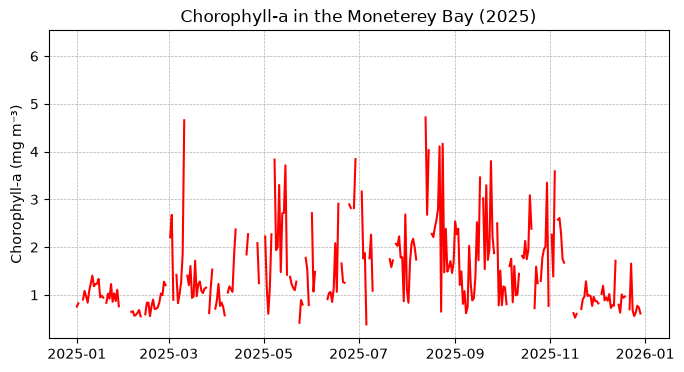

In [80]:
chlor_stillwater = np.nanmean(chlor, axis=(1,2))

dates = [] # make an empty list to hold some dates 

# loop through each Unix time
for t in time:

    # convert the Unix time to a date
    date = datetime(1970, 1, 1) + timedelta(days=int(t))

    # put the date in the dates list
    dates.append(date)

# recreate the figure using the new dates list
fig = plt.figure(figsize=(8,4))
plt.plot(dates, chlor_stillwater, color='red', linewidth=1.5)
plt.ylabel('Chorophyll-a (mg m⁻³)')
plt.grid(linestyle='--', linewidth=0.5)
plt.title('Chorophyll-a in the Moneterey Bay (2025)')
plt.show()


In [76]:
# create a function called create_panel that takes in the following arguments:
#       - timestep: date in the SST data (nc)
#       - output_file: a path to an output file (png)
def create_panel(timestep, output_file, save_as_image=True):

    
    # make the figure
    fig = plt.figure(figsize=(12,5))

    #make first subplot - chlor
    plt.subplot(1,2,1)
    C = plt.pcolormesh(longitude, latitude, chlor[timestep,:,:],
                       vmin=8, vmax=20, cmap='turbo')
    cbar = plt.colorbar(C)
    cbar.set_label('Chorophyll-a (mg m⁻³)')
    plt.plot(longitude[lon_index], latitude[lat_index], 'ko')
    plt.xlabel('Longitude')
    plt.ylabel('Latitude')
    plt.title('Chorophyll-a Concentration')
 

    #plot the timeseries
    plt.subplot(1,2,2)
    plt.plot(dates, chlor_stillwater, color = 'red')
    plt.plot(dates[timestep], chlor_stillwater[timestep], 'ko')
    plt.ylabel('Chorophyll-a (mg m⁻³)')
    plt.xlabel('Date')
    plt.grid(linestyle='--', linewidth=0.5)
    plt.title('Chlorophyll-a in the Monterey Bay')

    #make a title with date
    plt.suptitle(dates[timestep].strftime('%Y/%m/%d'))
    

    if save_as_image:
        # save the figure to the output_file
        plt.savefig(output_file)#, bbox_inches='tight')
    
        # close the figure
        plt.close(fig)
    else:
        plt.show()
        

In [77]:
# define a directory for this lab
lab_directory = '/Volumes/KatsDrive/Remote Sensing/Homework/HW11/Data'

# make a folder for ssha_panel08s
if 'chl_panels' not in os.listdir(lab_directory):
    os.mkdir(os.path.join(lab_directory, 'chl_panels'))

output_dir = os.path.join(lab_directory, 'chl_panels')

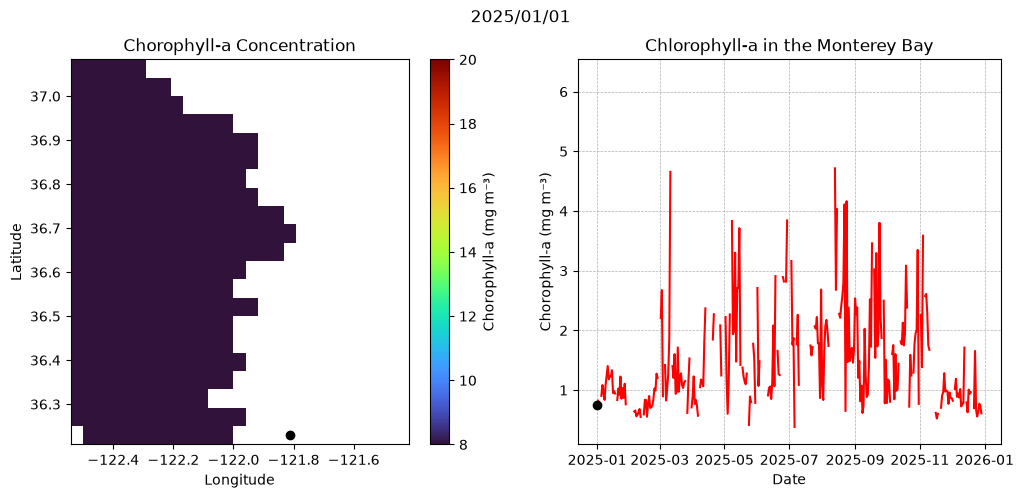

In [78]:
# define the input file path
timestep = 0

# define the output file path
output_file = os.path.join(lab_directory, 'chl_test.png')

# call the function to generate a plot
create_panel(timestep, output_file, save_as_image=False)